In [2]:
import os

import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import Image
import re
from wordfreq import zipf_frequency


sys.path.append("../src")
from surprisal import tok, lm, dev, full_surprisal, lossy_surprisal
from ns_data import load_stories
import surprisal

LAMS = [1, 2, 4, 8]

c:\Users\sarav\OneDrive\Documents\France\School\projects\lossy-context-surprisal\.pixi\envs\default\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 148/148 [00:01<00:00, 135.21it/s]


1(a) Probability of keeping a word

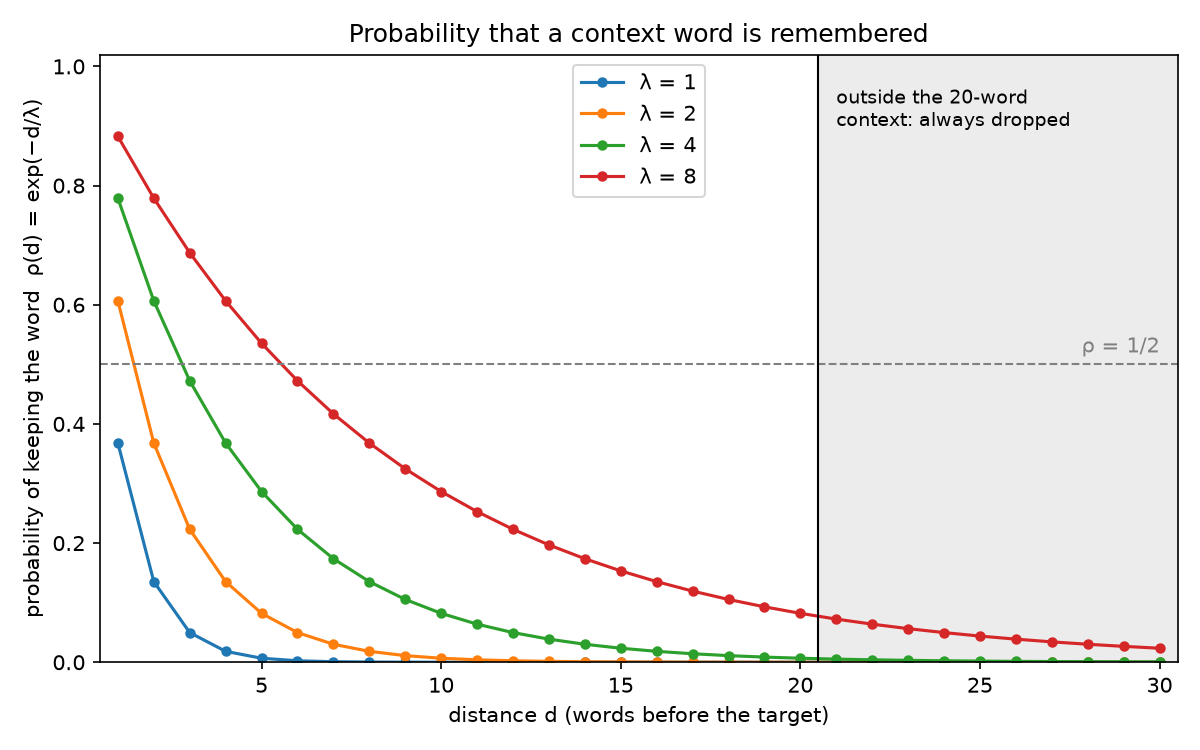

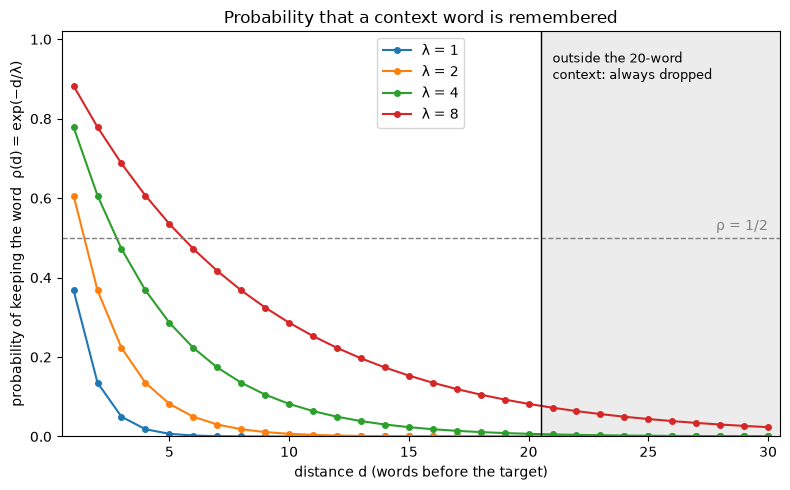

In [36]:
D = 20
d = np.arange(1, 31)

fig, ax = plt.subplots(figsize=(8, 5))
for lam in LAMS:
    ax.plot(d, np.exp(-d / lam), marker="o", markersize=4, label=f"λ = {lam}")
ax.axhline(0.5, color="gray", linestyle="--", linewidth=1)
ax.text(30, 0.52, "ρ = 1/2", ha="right", color="gray")
ax.axvline(D + 0.5, color="black", linewidth=1)
ax.axvspan(D + 0.5, d.max() + 0.5, color="gray", alpha=0.15)
ax.text(D + 1, 0.9, "outside the 20-word\ncontext: always dropped", fontsize=9)
ax.set_xlabel("distance d (words before the target)")
ax.set_ylabel("probability of keeping the word  ρ(d) = exp(−d/λ)")
ax.set_xlim(0.5, d.max() + 0.5)
ax.set_ylim(0, 1.02)
ax.set_title("Probability that a context word is remembered")
ax.legend()
plt.tight_layout()

os.makedirs("../figures", exist_ok=True)
plt.savefig("../figures/rho_curves.pdf")             # for the report
plt.savefig("../figures/rho_curves.png", dpi=150)    # to display here
Image("../figures/rho_curves.png")  # problem with matplotlib in my notebook, if display is done through .show, it crashes

In [37]:
for lam in LAMS:
    print(f"λ = {lam}: kept with probability 1/2 at d = {lam * np.log(2):.2f}, "
          f"previous word kept with probability {np.exp(-1 / lam):.2f}")

λ = 1: kept with probability 1/2 at d = 0.69, previous word kept with probability 0.37
λ = 2: kept with probability 1/2 at d = 1.39, previous word kept with probability 0.61
λ = 4: kept with probability 1/2 at d = 2.77, previous word kept with probability 0.78
λ = 8: kept with probability 1/2 at d = 5.55, previous word kept with probability 0.88


1(b) Full surprisal

In [38]:
stories = load_stories()
n_words = sum(len(w) for w in stories.values())
print(len(stories), "stories,", n_words, "words, device:", dev)

10 stories, 10256 words, device: cpu


In [39]:
# choosing a few words to examine

for w in ["England,", "boar's", "North", "long-bearded", "mountains."]:
    print(f"{w:15} -> {tok.tokenize(' ' + w)}")

England,        -> ['ĠEngland', ',']
boar's          -> ['Ġbo', 'ar', "'s"]
North           -> ['ĠNorth']
long-bearded    -> ['Ġlong', '-', 'be', 'arded']
mountains.      -> ['Ġmountains', '.']


In [40]:
# check what surprisal value each token has in England,

def token_surprisals(context_words, target):
    """Surprisal (bits) of each GPT-2 token of target after context_words."""
    ctx_ids = tok.encode(" ".join(context_words)) if context_words else []
    tgt_ids = tok.encode(" " + target)
    ids = [tok.bos_token_id] + ctx_ids + tgt_ids
    with torch.no_grad():
        logp = torch.log_softmax(lm(torch.tensor([ids]).to(dev)).logits[0], dim=-1)
    first = len(ids) - len(tgt_ids)          # position of the first target token
    # the prediction for position p is made at position p - 1
    return [(tok.decode([t]), -logp[first + j - 1, t].item() / np.log(2))
            for j, t in enumerate(tgt_ids)]

s = stories[1]
i = 9                                        # s[9] = 'England,'
parts = token_surprisals(s[:i], s[i])
for token, bits in parts:
    print(f"{token!r:12} {bits:6.2f} bits")
print("sum of tokens :", round(sum(b for _, b in parts), 4))
print("full_surprisal:", round(full_surprisal(s[:i], s[i]), 4))

' England'     2.38 bits
','            2.20 bits
sum of tokens : 4.5876
full_surprisal: 4.5876


In [41]:
def surp_full_story(words):
    """Full surprisal of every word of one story (context = words before it)."""
    return [full_surprisal(words[:i], words[i]) for i in range(len(words))]

test = surp_full_story(stories[1][:20])
for w, v in zip(stories[1][:20], test):
    print(f"{w:12} {v:6.2f}")

If            13.74
you            0.81
were           5.42
to             2.09
journey       14.62
to             2.14
the            2.67
North          6.57
of             7.01
England,       4.59
you            1.61
would          1.35
come           6.17
to             3.18
a              2.64
valley         9.84
that           4.25
is             2.35
surrounded     6.98
by             0.14


In [42]:
full_dir = Path("../results/surp_full")
full_dir.mkdir(parents=True, exist_ok=True)

for story, words in stories.items():
    path = full_dir / f"story_{story}.csv"
    if path.exists():
        print(f"story {story}: already done")
        continue
    t0 = time.time()
    pd.DataFrame({"story": story,
                  "zone": range(1, len(words) + 1),   # position in the story
                  "word": words,
                  "surp_full": surp_full_story(words)}).to_csv(path, index=False)
    print(f"story {story}: {len(words)} words in {time.time() - t0:.0f} s")

surp = pd.concat([pd.read_csv(p) for p in full_dir.glob("story_*.csv")])
surp = surp.sort_values(["story", "zone"]).reset_index(drop=True)
surp.to_csv("../results/ns_surp_full.csv", index=False)

story 1: already done
story 2: already done
story 3: already done
story 4: already done
story 5: already done
story 6: already done
story 7: already done
story 8: already done
story 9: already done
story 10: already done


In [43]:
assert len(surp) == n_words, "some words are missing"
assert (surp["surp_full"] > 0).all()

print(surp["surp_full"].describe().round(2))
print(surp.nsmallest(5, "surp_full")[["word", "surp_full"]])   # most predictable
print(surp.nlargest(5, "surp_full")[["word", "surp_full"]])    # most surprising
print(surp[surp["zone"] == 1][["story", "word", "surp_full"]]) # first words: empty context

count    10256.00
mean         5.51
std          4.33
min          0.00
25%          2.16
50%          4.59
75%          7.92
max         40.52
Name: surp_full, dtype: float64
        word  surp_full
9957   least   0.000318
10055     of   0.000757
7922      to   0.001110
828       of   0.001281
4634      to   0.001281
                         word  surp_full
4282              Correthers,  40.519834
7899  internally-inconsistent  37.451394
8494                Couleren,  35.870621
2511               'Scratch!'  33.293667
9722              coprolalia,  31.443744
      story        word  surp_full
0         1          If  13.741723
1073      2           A  12.856137
2063      3          It  12.627925
3103      4        Once  16.874438
4188      5          At  16.035086
5201      6        This  12.700890
6300      7         The  11.094198
7299      8         The  11.094198
8279      9       Tulip  24.881169
9317     10  Tourette's  28.293815


In [44]:
row = surp.loc[9957]
story, zone = row["story"], row["zone"]

# the 4 words before it and 2 after, in the same story
around = surp[(surp["story"] == story) & surp["zone"].between(zone - 4, zone + 2)]
print(" ".join(around["word"]))
print(around[["zone", "word", "surp_full"]].round(3))

vocal tics for at least one year.
      zone   word  surp_full
9953   637  vocal      9.258
9954   638   tics      0.989
9955   639    for      3.445
9956   640     at      1.491
9957   641  least      0.000
9958   642    one      3.789
9959   643  year.      1.492


1(c) Lossy surprisal

In [45]:
def lossy_story(story, words):
    """Lossy surprisal of every word of one story, for each lambda."""
    rows = []
    for i in range(len(words)):
        row = {"story": story, "zone": i + 1, "word": words[i]}
        for lam in LAMS:
            # fixed seed for each (story, word, lambda): same result every time we run it
            surprisal.rng = np.random.default_rng([story, i + 1, lam])
            row[f"surp_lam{lam}"] = lossy_surprisal(words[:i], words[i], lam=lam)
        rows.append(row)
    return pd.DataFrame(rows)

In [46]:
"""t0 = time.time()
test = lossy_story(1, stories[1][:40])
sec = (time.time() - t0) / 40
print(test.head(10))

# same input -> same output, thanks to the seeds
print("reproducible:", test.equals(lossy_story(1, stories[1][:40])))

print(f"{sec:.2f} s/word -> about {sec * n_words / 3600:.1f} h for everything")"""

't0 = time.time()\ntest = lossy_story(1, stories[1][:40])\nsec = (time.time() - t0) / 40\nprint(test.head(10))\n\n# same input -> same output, thanks to the seeds\nprint("reproducible:", test.equals(lossy_story(1, stories[1][:40])))\n\nprint(f"{sec:.2f} s/word -> about {sec * n_words / 3600:.1f} h for everything")'

In [47]:
lossy_dir = Path("../results/surp_lossy")
lossy_dir.mkdir(parents=True, exist_ok=True)

In [48]:
RUN_LOSSY = False   # the full lossy run was done on Colab
if RUN_LOSSY:
    for story, words in stories.items():
        path = lossy_dir / f"story_{story}.csv"
        if path.exists():
            print(f"story {story}: already done")
            continue
        t0 = time.time()
        lossy_story(story, words).to_csv(path, index=False)
        print(f"story {story}: {len(words)} words in {time.time() - t0:.0f} s")

In [49]:
lossy = pd.concat([pd.read_csv(p) for p in lossy_dir.glob("story_*.csv")])
lossy = lossy.sort_values(["story", "zone"]).reset_index(drop=True)
lossy.to_csv("../results/ns_surp_lossy.csv", index=False)

In [50]:
both = surp.merge(lossy, on=["story", "zone", "word"])
cols = ["surp_full"] + [f"surp_lam{lam}" for lam in LAMS]

# 1. on a few words: does lossy get closer to full as lambda grows?
print(both[["word"] + cols].sample(10, random_state=0).round(2))

# 2. on average
print(both[cols].mean().round(2))

# 3. is lossy larger than full for every word? (% of words where it is)
for lam in LAMS:
    pct = (both[f"surp_lam{lam}"] > both["surp_full"]).mean() * 100
    print(f"λ = {lam}: lossy > full for {pct:.0f}% of words")

         word  surp_full  surp_lam1  surp_lam2  surp_lam4  surp_lam8
4556    store       3.15      16.66      12.09       9.24       7.85
8164     with       6.35       9.79       8.98       8.80       7.25
6426  driving       9.73      17.72      15.14      11.27      10.72
9926       as       0.02       8.99       6.77       4.38       1.75
1813       an       5.85      10.18       9.07       6.32       7.16
7869     have       0.45      10.57       7.73       5.79       4.86
4075   should       8.94      12.93      13.20      12.00      10.61
1611     down      10.96      15.86      12.65      11.10      10.86
4328     hour       0.02      12.34       9.73       4.28       2.61
8557      now       6.76      12.30      10.11       7.97       7.42
surp_full     5.51
surp_lam1    14.77
surp_lam2    12.18
surp_lam4    10.30
surp_lam8     8.93
dtype: float64
λ = 1: lossy > full for 99% of words
λ = 2: lossy > full for 98% of words
λ = 4: lossy > full for 96% of words
λ = 8: lossy > full 

In [51]:
for lam in LAMS:
    lossy_col, full_col = both[f"surp_lam{lam}"], both["surp_full"]
    tie = np.isclose(lossy_col, full_col, atol=1e-3)
    larger = (lossy_col > full_col) & ~tie
    smaller = (lossy_col < full_col) & ~tie
    positions = both.loc[tie, "zone"].tolist()
    print(f"λ = {lam}: larger {larger.mean():.1%}, smaller {smaller.mean():.1%}, "
          f"equal {tie.sum()} words, positions {positions}")

λ = 1: larger 99.4%, smaller 0.5%, equal 10 words, positions [1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
λ = 2: larger 97.8%, smaller 2.1%, equal 12 words, positions [1, 1, 1, 1, 1, 1, 570, 1, 1, 116, 1, 1]
λ = 4: larger 95.8%, smaller 4.1%, equal 11 words, positions [1, 1, 1, 843, 1, 1, 1, 1, 1, 1, 1]
λ = 8: larger 92.7%, smaller 7.2%, equal 12 words, positions [1, 1, 1, 1, 1, 1, 2, 1, 1, 1, 912, 1]


In [52]:
for lam in LAMS:
    col = f"surp_lam{lam}"
    tie = np.isclose(both[col], both["surp_full"], atol=1e-3)
    ties = both[tie & (both["zone"] > 1)]          # skip first words, already explained
    print(f"λ = {lam}: {len(ties)} tied words that are not the first word of a story")

    for _, row in ties.iterrows():
        same_story = both["story"] == row["story"]
        before = both[same_story & both["zone"].between(row["zone"] - 4, row["zone"] - 1)]["word"]
        after = both[same_story & both["zone"].between(row["zone"] + 1, row["zone"] + 2)]["word"]
        line = " ".join(before) + f" [{row['word']}] " + " ".join(after)
        print(f"    story {row['story']}, position {row['zone']}: {line.strip():50} "
              f"full = {row['surp_full']:.4f}   lossy = {row[col]:.4f}")
    print()

λ = 1: 0 tied words that are not the first word of a story

λ = 2: 2 tied words that are not the first word of a story
    story 6, position 570: when she heard the [bad] news. 'He'll              full = 12.5874   lossy = 12.5873
    story 8, position 116: turned into a widely [known] pop culture           full = 7.1260   lossy = 7.1264

λ = 4: 1 tied words that are not the first word of a story
    story 3, position 843: whole bundle of matches, [in] order to             full = 7.5483   lossy = 7.5486

λ = 8: 2 tied words that are not the first word of a story
    story 6, position 2: This [is] a story                                  full = 2.4453   lossy = 2.4453
    story 9, position 912: arguing that the price [changes] may not           full = 9.6570   lossy = 9.6578



In [53]:
lam = 2
col = f"surp_lam{lam}"

both = both.sort_values(["story", "zone"]).reset_index(drop=True)
smaller = both[both[col] < both["surp_full"]]
print(f"λ = {lam}: {len(smaller)} words where lossy < full\n")

for _, row in smaller.sample(10, random_state=0).iterrows():
    same_story = both["story"] == row["story"]
    before = both[same_story & both["zone"].between(row["zone"] - 5, row["zone"] - 1)]["word"]
    after = both[same_story & both["zone"].between(row["zone"] + 1, row["zone"] + 5)]["word"]

    line = " ".join(before) + f" [{row['word']}] " + " ".join(after)
    print(f"{line.strip():50}  full = {row['surp_full']:5.2f}   lossy = {row[col]:5.2f}")

λ = 2: 219 words where lossy < full

to take place, Jill filled [with] excitement while Lucy regretted that  full =  5.83   lossy =  5.52
meeting, because he was the [dark] horse for king. The small  full = 14.67   lossy = 13.76
things she had seen, nor [into] what glory she had entered  full = 14.61   lossy = 13.47
threatened to take over, the [text] messages, and the way they  full = 16.00   lossy = 12.83
tap the message straight into [oblivion] where it belonged.  full = 18.35   lossy = 15.36
that was what it said [to] Lucy. It said that and   full =  7.64   lossy =  5.65
burst into a flame, and [lo] and behold, the girl was  full = 14.06   lossy = 13.78
voice,' her mother had argued [two] months back, when the concert  full = 11.67   lossy = 11.30
co-occurs with. An important role [in] Tourette's gene expression is played  full =  6.20   lossy =  5.96
who was breathing fire all [on] account of the little snail,  full =  8.88   lossy =  8.84


1(d) Areas of interest: Marking verbs and their distances to subjects

In [54]:
UD_FILE = "../data/naturalstories/parses/ud/stories-aligned.conllx"

def read_ud(path):
    """List of sentences; each sentence is a list of tokens (dicts)."""
    sentences, current = [], []
    for line in open(path, encoding="utf-8"):
        line = line.rstrip("\n")
        if line == "":                      # an empty line ends a sentence
            if current:
                sentences.append(current)
                current = []
            continue
        cols = line.split("\t")
        story, zone = cols[9].replace("TokenId=", "").split(".")[:2]   # 'TokenId=1.10.2' -> 1, 10
        current.append({"id": int(cols[0]), "word": cols[1], "tag": cols[4],
                        "head": int(cols[6]), "rel": cols[7],
                        "story": int(story), "zone": int(zone)})
    if current:
        sentences.append(current)
    return sentences

sentences = read_ud(UD_FILE)
print(len(sentences), "sentences")

485 sentences


In [55]:
rows = []
for sent in sentences:
    for verb in sent:
        if not verb["tag"].startswith("VB"):          # VB, VBD, VBZ, VBN, ...
            continue
        subjects = [t for t in sent
                    if t["head"] == verb["id"]                  # depends on this verb
                    and t["rel"] in ("nsubj", "nsubjpass")      # as its subject
                    and t["id"] < verb["id"]]                   # to its left
        if not subjects:
            continue
        subj = max(subjects, key=lambda t: t["id"])   # if several, the closest one
        # words between them = difference of positions - 1 (punctuation is inside zones, so not counted)
        distance = max(verb["zone"] - subj["zone"] - 1, 0)
        rows.append({"story": verb["story"], "zone": verb["zone"], "verb": verb["word"],
                     "subject": subj["word"], "distance": distance})

aoi = pd.DataFrame(rows)
aoi["aoi"] = 1
aoi.to_csv("../results/ns_aoi.csv", index=False)
print(len(aoi), "verbs with a subject to their left")
print(aoi.sample(8, random_state=0).to_string(index=False))

928 verbs with a subject to their left
 story  zone     verb   subject  distance  aoi
     4   207  decided        it         1    1
     4   667   played        he         0    1
     7   543     come   message         1    1
    10   709  include     which         0    1
     9   490 occurred purchases         0    1
     3   502   seemed        It         0    1
     3   852      saw      girl         0    1
     1   201    liked      boar         1    1


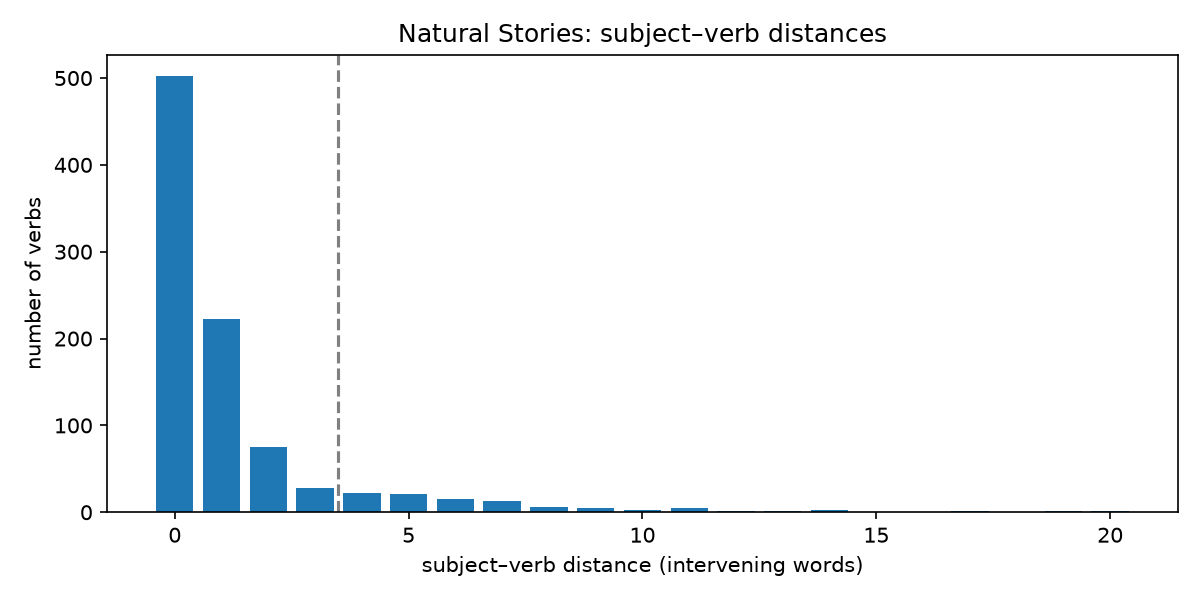

In [56]:
counts = aoi["distance"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(counts.index, counts.values)
ax.axvline(3.5, color="gray", linestyle="--")       # left: 0-3, right: 4 or more
ax.set_xlabel("subject–verb distance (intervening words)")
ax.set_ylabel("number of verbs")
ax.set_title("Natural Stories: subject–verb distances")
plt.tight_layout()

plt.savefig("../figures/ns_distances.pdf")             # for the report
plt.savefig("../figures/ns_distances.png", dpi=150)    # to display here
plt.close(fig)

Image("../figures/ns_distances.png")

Comparing with StructuralCost dataset

In [57]:
SC_DIR = Path("../data/structuralcost")

crit = pd.read_csv(SC_DIR / "StructuralCost_critical.csv")
ctrl = pd.read_csv(SC_DIR / "StructuralCost_control.csv")
sc = pd.concat([crit, ctrl], ignore_index=True)    # same columns, so they stack
sc["item"] = sc["tag"] + "_" + sc["setID"].astype(str)    # e.g. "critical_1", "control_1"

print(sc["tag"].unique())                          # the split names, critical vs control
print(sc["item"].nunique())
print(sc.groupby("tag")["sentence_structure"].unique())

<StringArray>
['exp-1', 'exp-2']
Length: 2, dtype: str
90
tag
exp-1    [nested-subject, standard-object, nested-objec...
exp-2                      [pp-short, pp-long, baseline-2]
Name: sentence_structure, dtype: object


In [58]:
# one row per sentence (each row of sc is one word read by one participant)
sents = sc.drop_duplicates("sentID_in_dataset")
print(len(sents), "sentences")                                       # should be 450
print((sents["dep_length"] == sents["root_i"] - sents["nsubj_i"] - 1).mean())   # 1.0 = same definition as NS

for name, d in [("Natural Stories", aoi["distance"]), ("StructuralCost", sents["dep_length"])]:
    n_long = (d >= 4).sum()
    print(f"{name}: {n_long} of {len(d)} ({n_long / len(d):.0%}) have a distance of 4 or more")

450 sentences
1.0
Natural Stories: 100 of 928 (11%) have a distance of 4 or more
StructuralCost: 360 of 450 (80%) have a distance of 4 or more


1(e) Table for the regressions

In [59]:
surp_cols = ["surp_full"] + [f"surp_lam{lam}" for lam in LAMS]

w = both[["story", "zone", "word"] + surp_cols].sort_values(["story", "zone"]).reset_index(drop=True)
w["freq"] = [zipf_frequency(x, "en") for x in w["word"]]          # Zipf scale, punctuation ignored
w["length"] = [len(re.sub(r"[^\w]", "", x)) for x in w["word"]]   # letters only: 'England,' -> 7

# value on the previous word of the same story (empty for the first word of a story)
for c in ["freq", "length"] + surp_cols:
    w[f"{c}_prev"] = w.groupby("story")[c].shift(1)

print(w.head(3).T)

                        0          1          2
story                   1          1          1
zone                    1          2          3
word                   If        you       were
surp_full       13.741723   0.808684   5.417629
surp_lam1       13.741716   9.145533  13.147781
surp_lam2       13.741716   6.168103  10.327749
surp_lam4       13.741716    4.97713   7.616732
surp_lam8       13.741716   2.595186    5.94652
freq                 6.47       6.98       6.34
length                  2          3          4
freq_prev             NaN       6.47       6.98
length_prev           NaN        2.0        3.0
surp_full_prev        NaN  13.741723   0.808684
surp_lam1_prev        NaN  13.741716   9.145533
surp_lam2_prev        NaN  13.741716   6.168103
surp_lam4_prev        NaN  13.741716    4.97713
surp_lam8_prev        NaN  13.741716   2.595186


In [60]:
rt = pd.read_csv("../data/naturalstories/naturalstories_RTS/processed_RTs.tsv", sep="\t",
                 usecols=["WorkerId", "item", "zone", "RT"])
rt = rt.rename(columns={"WorkerId": "subject", "item": "story"})   # 'item' in this file = story
rt = rt[rt["RT"].between(100, 3000)]                               # same limits as StructuralCost
rt["logRT"] = np.log(rt["RT"])
print(len(rt), "readings,", rt["subject"].nunique(), "participants")

848875 readings, 180 participants


In [61]:
verbs = w.merge(aoi[["story", "zone", "distance"]], on=["story", "zone"])    # the 928 AOI verbs
d = rt.merge(verbs, on=["story", "zone"])                                    # x participants
d["item"] = d["story"].astype(str) + "_" + d["zone"].astype(str)             # one id per verb, e.g. '1_3'

predictors = (["freq", "length", "freq_prev", "length_prev", "distance"]
              + surp_cols + [f"{c}_prev" for c in surp_cols])
for c in predictors:
    d[c] = (d[c] - d[c].mean()) / d[c].std()                                 # z-score

d = d[["subject", "item", "story", "zone", "word", "logRT"] + predictors]
d.to_csv("../results/ns_verbs.csv", index=False)

print(len(d), "rows,", d["subject"].nunique(), "participants,", d["item"].nunique(), "verbs")
assert d[predictors].notna().all().all(), "some predictor is empty"

77371 rows, 180 participants, 928 verbs


In [3]:
# check that the values on the table look normal 
d = pd.read_csv("../results/ns_verbs.csv")
print(d.shape, d["subject"].nunique(), "participants,", d["item"].nunique(), "verbs")   # 928 verbs
print(d.isna().sum().sum(), "empty values")                                            # should be 0
print(np.exp(d["logRT"]).describe().round(0))                                          # RTs between 100 and 3000
print(d.drop(columns=["subject", "item", "story", "zone", "word", "logRT"])
       .agg(["mean", "std"]).round(2).T)                                                # all means 0, std 1

(77371, 21) 180 participants, 928 verbs
0 empty values
count    77371.0
mean       335.0
std        165.0
min        101.0
25%        237.0
50%        297.0
75%        389.0
max       2968.0
Name: logRT, dtype: float64
                mean  std
freq             0.0  1.0
length          -0.0  1.0
freq_prev        0.0  1.0
length_prev      0.0  1.0
distance        -0.0  1.0
surp_full        0.0  1.0
surp_lam1       -0.0  1.0
surp_lam2       -0.0  1.0
surp_lam4       -0.0  1.0
surp_lam8        0.0  1.0
surp_full_prev   0.0  1.0
surp_lam1_prev   0.0  1.0
surp_lam2_prev   0.0  1.0
surp_lam4_prev   0.0  1.0
surp_lam8_prev  -0.0  1.0
